# Principal component analysis of amino acid frequencies of CDR1 and CDR2 sequences of V-genes from the IGHV1 and IGHV3 families.

In [1]:
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sn

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from itertools import product

nucleotides = ['A', 'T', 'G', 'C']
nucl_comb = list(product(nucleotides, repeat = 3))
nucl_comb = ["".join(c) for c in nucl_comb]

### cdrs
cdrs_table = pd.read_csv('data/IMGT_CDR_IGHV.tsv', sep="\t")
cdrs_table = cdrs_table[cdrs_table['type'] == 'F']
cdrs_table = cdrs_table[['gene', 'CDR', 'n_length', 'reading_frame', 'aa_length', 'aa_sequence',
                         'nt_sequence']].drop_duplicates().reset_index(drop=True)
cdrs_table["gene_class"] = cdrs_table["gene"].str.strip().str[4]

In [2]:
codon_freq_df = []

for i in range(len(cdrs_table)):
    i_codons = dict()
    for codon in nucl_comb:
        i_codons[codon] = 0
    nt_seq = cdrs_table['nt_sequence'].iloc[i]
    i_frame = cdrs_table['reading_frame'].iloc[i]-1
    for j in range(i_frame, len(nt_seq), 3):
        if len(nt_seq[j:j+3]) == 3:
            if 'N' not in nt_seq[j:j+3]:
                i_codons[nt_seq[j:j+3]] = i_codons[nt_seq[j:j+3]] + 1
    i_gene_class = cdrs_table['gene_class'].iloc[i]
    i_cdr = cdrs_table['CDR'].iloc[i]
    i_gene = cdrs_table['gene'].iloc[i]
    i_codons['gene_class'] = i_gene_class
    i_codons['CDR'] = i_cdr
    i_codons['gene'] = i_gene
    codon_freq_df.append(i_codons)
codon_freq_df = pd.DataFrame(codon_freq_df)

0.9999999999999998 1.0 1.0
Explained variance: [0.10772119 0.08297164 0.06654731]


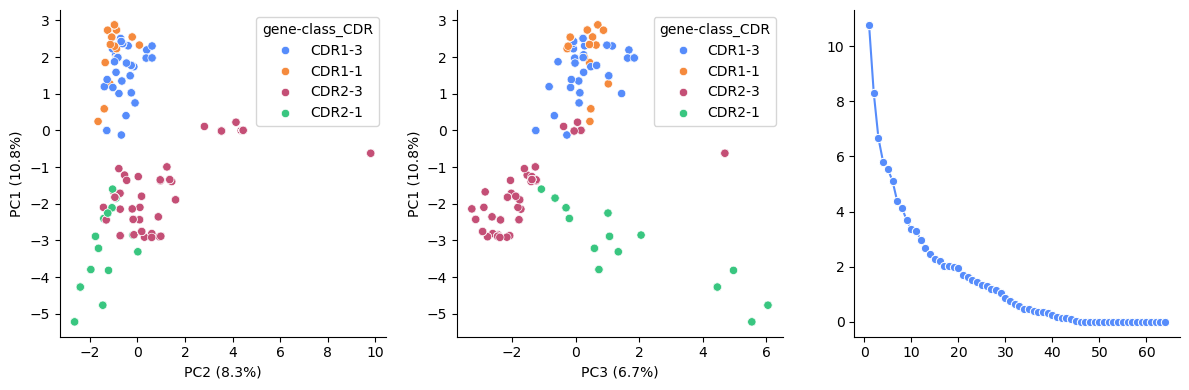

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

nucl_freq = codon_freq_df[(codon_freq_df['gene_class'] == '1')
                          | (codon_freq_df['gene_class'] == '3')]
nucl_freq = nucl_freq[(nucl_freq['CDR'] != 'CDR3')]

nucl_freq['gene-class_CDR'] = nucl_freq['CDR'] + '-' + nucl_freq['gene_class']
X = nucl_freq[nucl_comb].to_numpy()

## Each row should sum to ~1
row_sums = X.sum(axis=1, keepdims=True)
X_freq = X / X.sum(axis=1, keepdims=True)
print(X_freq.sum(axis=1).min(), np.median(X_freq.sum(axis=1)), X_freq.sum(axis=1).max())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_freq)

pca = PCA(n_components=64, random_state=0)
X_pca = pca.fit_transform(X_scaled)
components = range(1, len(pca.explained_variance_ratio_) + 1)
print("Explained variance:", pca.explained_variance_ratio_[:3])

df_pca = nucl_freq[['gene_class', 'CDR', 'gene', 'gene-class_CDR']].copy()
df_pca['PC1'] = X_pca[:, 0]
df_pca['PC2'] = X_pca[:, 1]
df_pca['PC3'] = X_pca[:, 2]

sn.scatterplot(data = df_pca, x = 'PC2', y = 'PC1', hue = 'gene-class_CDR', ax = axes[0])
axes[0].set_xlabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].set_ylabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')

sn.scatterplot(data = df_pca, x = 'PC3', y = 'PC1', hue = 'gene-class_CDR', ax = axes[1])
axes[1].set_xlabel(f'PC3 ({pca.explained_variance_ratio_[2]*100:.1f}%)')
axes[1].set_ylabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')

sn.lineplot(x = components, y = pca.explained_variance_ratio_*100, marker = 'o', ax = axes[2])
sn.scatterplot(x = components, y = pca.explained_variance_ratio_*100, ax = axes[2])

sn.despine()
plt.tight_layout()